<a href="https://colab.research.google.com/github/ABJINI2506/Household_Electric_Power_Consumption/blob/main/Household_Electric_Power_Consumption.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import zipfile
import io

from google.colab import files

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("Libraries imported successfully")

Libraries imported successfully


In [5]:
uploaded = files.upload()

Saving household_power_consumption.txt to household_power_consumption.txt


In [6]:
import os

print(os.listdir("/content"))

['.config', 'household_power_consumption.txt', 'sample_data']


In [7]:
df = pd.read_csv(
    "/content/household_power_consumption.txt",
    sep=";",
    na_values=["?"],
    low_memory=False
)

print("Dataset loaded successfully")
print("Dataset shape:", df.shape)
print(df.head())

Dataset loaded successfully
Dataset shape: (2075259, 9)
         Date      Time  Global_active_power  Global_reactive_power  Voltage  \
0  16/12/2006  17:24:00                4.216                  0.418   234.84   
1  16/12/2006  17:25:00                5.360                  0.436   233.63   
2  16/12/2006  17:26:00                5.374                  0.498   233.29   
3  16/12/2006  17:27:00                5.388                  0.502   233.74   
4  16/12/2006  17:28:00                3.666                  0.528   235.68   

   Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3  
0              18.4             0.0             1.0            17.0  
1              23.0             0.0             1.0            16.0  
2              23.0             0.0             2.0            17.0  
3              23.0             0.0             1.0            17.0  
4              15.8             0.0             1.0            17.0  


In [8]:
df["Timestamp"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    dayfirst=True,
    errors="coerce"
)

df = df.drop(columns=["Date", "Time"])

numeric_columns = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["Timestamp"])
df = df.sort_values("Timestamp")
df = df.set_index("Timestamp")
df = df.asfreq("min")

df[numeric_columns] = df[numeric_columns].interpolate(
    method="time",
    limit_direction="both"
)

df = df.dropna(subset=numeric_columns)
df = df.iloc[:10000].copy()

print("Selected records:", len(df))
print("Missing values:", df[numeric_columns].isnull().sum().sum())
print(df.head())

Selected records: 10000
Missing values: 0
                     Global_active_power  Global_reactive_power  Voltage  \
Timestamp                                                                  
2006-12-16 17:24:00                4.216                  0.418   234.84   
2006-12-16 17:25:00                5.360                  0.436   233.63   
2006-12-16 17:26:00                5.374                  0.498   233.29   
2006-12-16 17:27:00                5.388                  0.502   233.74   
2006-12-16 17:28:00                3.666                  0.528   235.68   

                     Global_intensity  Sub_metering_1  Sub_metering_2  \
Timestamp                                                               
2006-12-16 17:24:00              18.4             0.0             1.0   
2006-12-16 17:25:00              23.0             0.0             1.0   
2006-12-16 17:26:00              23.0             0.0             2.0   
2006-12-16 17:27:00              23.0             0.0       

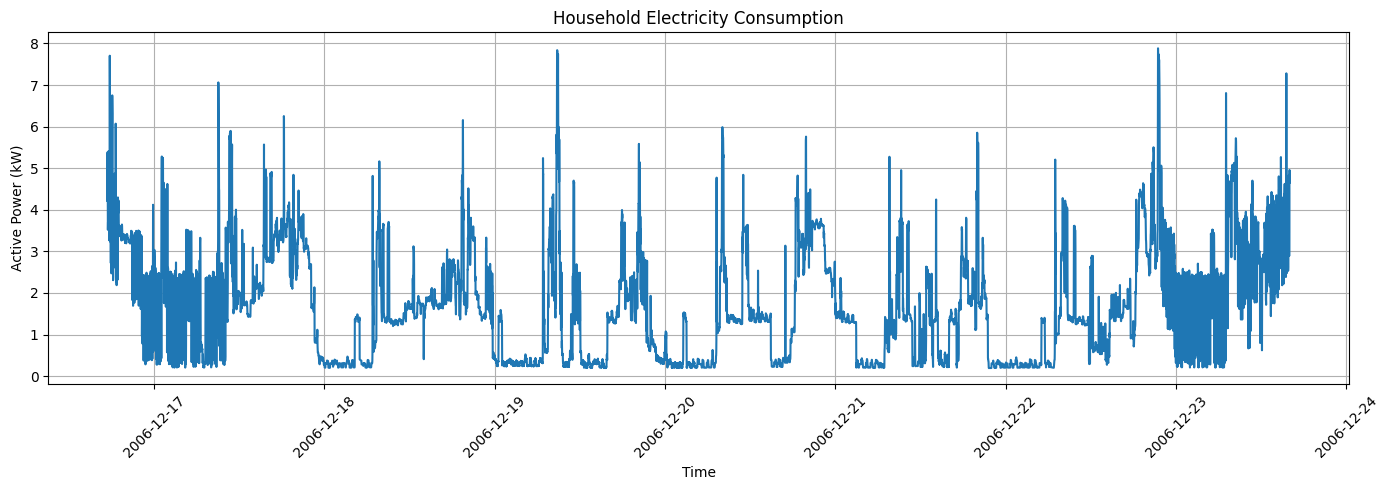

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(df.index, df["Global_active_power"])

plt.xlabel("Time")
plt.ylabel("Active Power (kW)")
plt.title("Household Electricity Consumption")
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [10]:
from sklearn.preprocessing import MinMaxScaler

features = numeric_columns
target = "Global_active_power"
target_index = features.index(target)

split1 = int(len(df) * 0.70)
split2 = int(len(df) * 0.85)

train_df = df.iloc[:split1]
val_df = df.iloc[split1:split2]
test_df = df.iloc[split2:]

scaler = MinMaxScaler()
scaler.fit(train_df[features])

train_scaled = scaler.transform(train_df[features])
val_scaled = scaler.transform(val_df[features])
test_scaled = scaler.transform(test_df[features])

print("Training records:", len(train_df))
print("Validation records:", len(val_df))
print("Testing records:", len(test_df))
print("Normalization completed")

Training records: 7000
Validation records: 1500
Testing records: 1500
Normalization completed


In [11]:
import numpy as np

sequence_length = 60

def create_sequences(data, sequence_length, target_index):
    X = []
    y = []

    for i in range(sequence_length, len(data)):
        X.append(data[i - sequence_length:i])
        y.append(data[i, target_index])

    return np.array(X), np.array(y)

X_train, y_train = create_sequences(
    train_scaled, sequence_length, target_index
)

X_val, y_val = create_sequences(
    val_scaled, sequence_length, target_index
)

X_test, y_test = create_sequences(
    test_scaled, sequence_length, target_index
)

print("Training input:", X_train.shape)
print("Training output:", y_train.shape)
print("Validation input:", X_val.shape)
print("Testing input:", X_test.shape)

Training input: (6940, 60, 7)
Training output: (6940,)
Validation input: (1440, 60, 7)
Testing input: (1440, 60, 7)


In [12]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

model = Sequential([
    LSTM(64, input_shape=(sequence_length, len(features))),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,545 (80.25 KB)

 Trainable params: 20,545 (80.25 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=64,
    callbacks=[early_stop],
    shuffle=False,
    verbose=1
)

print("Model training completed")

Epoch 1/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 6s 39ms/step - loss: 0.0130 - mae: 0.0783 - val_loss: 0.0040 - val_mae: 0.0390
Epoch 2/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 5s 47ms/step - loss: 0.0063 - mae: 0.0527 - val_loss: 0.0032 - val_mae: 0.0294
Epoch 3/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - loss: 0.0050 - mae: 0.0447 - val_loss: 0.0027 - val_mae: 0.0261
Epoch 4/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - loss: 0.0046 - mae: 0.0421 - val_loss: 0.0025 - val_mae: 0.0249
Epoch 5/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 7s 49ms/step - loss: 0.0045 - mae: 0.0422 - val_loss: 0.0024 - val_mae: 0.0231
Epoch 6/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/step - loss: 0.0045 - mae: 0.0416 - val_loss: 0.0024 - val_mae: 0.0263
Epoch 7/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - loss: 0.0042 - mae: 0.0397 - val_loss: 0.0023 - val_mae: 0.0246
Epoch 8/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - loss: 0.0041 - mae: 0.0390 - val_loss: 0.0021 - val_mae: 0.0220
Epoch 9/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 4s 34ms/

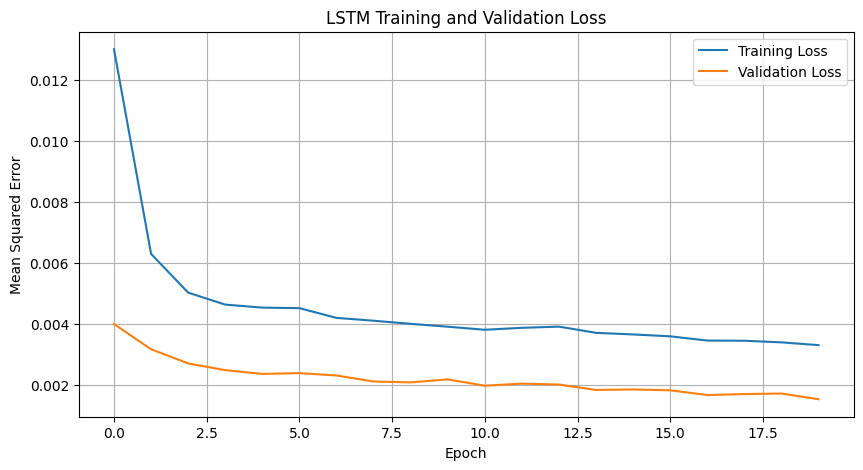

In [14]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.title("LSTM Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [15]:
predicted_scaled = model.predict(X_test)

target_min = scaler.data_min_[target_index]
target_range = scaler.data_range_[target_index]

actual = y_test * target_range + target_min

predicted = (
    predicted_scaled.flatten() * target_range + target_min
)

print("Actual consumption:", actual[:10])
print("Predicted consumption:", predicted[:10])

45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step
Actual consumption: [1.486 1.492 2.192 1.5   1.498 1.492 1.484 1.476 1.484 1.424]
Predicted consumption: [1.2486249  1.30320067 1.31074574 1.75253514 1.41816082 1.3513035
 1.32225197 1.3109048  1.29092129 1.28753095]


In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(actual, predicted)

rmse = np.sqrt(
    mean_squared_error(actual, predicted)
)

print("Mean Absolute Error (MAE):", round(mae, 4), "kW")
print("Root Mean Squared Error (RMSE):", round(rmse, 4), "kW")

Mean Absolute Error (MAE): 0.6978 kW
Root Mean Squared Error (RMSE): 0.8319 kW


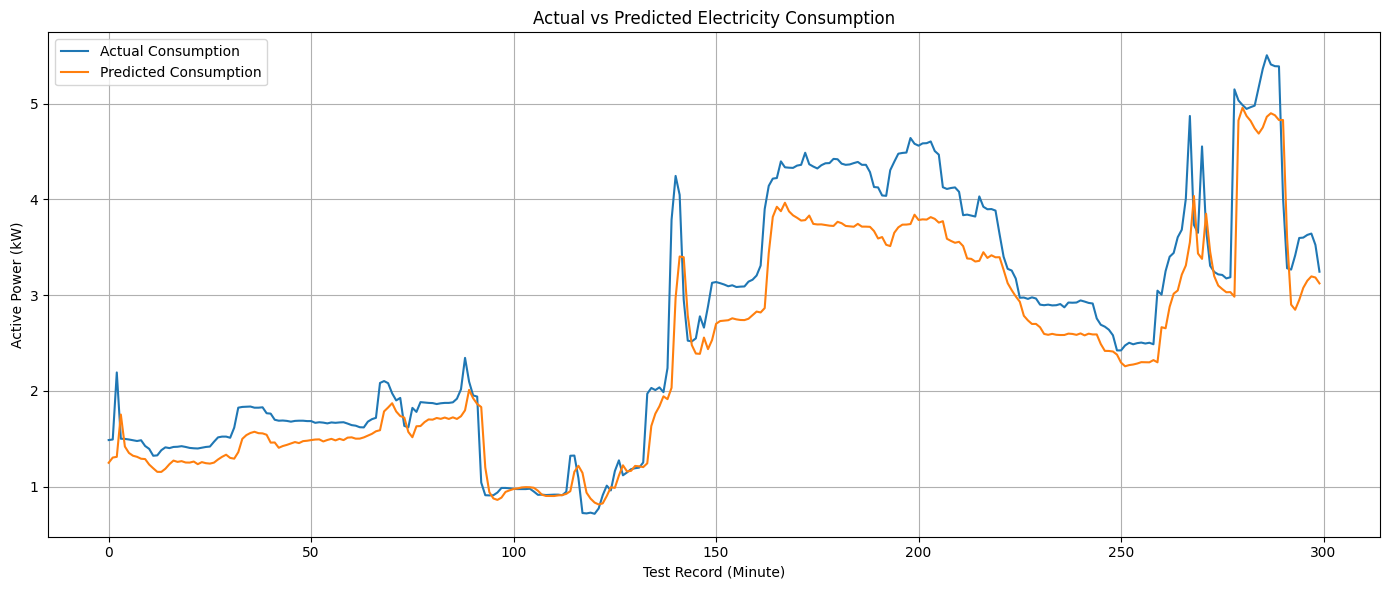

In [17]:
plt.figure(figsize=(14, 6))

plt.plot(actual[:300], label="Actual Consumption")
plt.plot(predicted[:300], label="Predicted Consumption")

plt.xlabel("Test Record (Minute)")
plt.ylabel("Active Power (kW)")
plt.title("Actual vs Predicted Electricity Consumption")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [18]:
results = pd.DataFrame({
    "Timestamp": test_df.index[sequence_length:],
    "Actual_Consumption_kW": actual,
    "Predicted_Consumption_kW": predicted
})

print(results.head(10))

results.to_csv(
    "electricity_forecast_results.csv",
    index=False
)

print("Forecast results saved successfully")

            Timestamp  Actual_Consumption_kW  Predicted_Consumption_kW
0 2006-12-22 16:04:00                  1.486                  1.248625
1 2006-12-22 16:05:00                  1.492                  1.303201
2 2006-12-22 16:06:00                  2.192                  1.310746
3 2006-12-22 16:07:00                  1.500                  1.752535
4 2006-12-22 16:08:00                  1.498                  1.418161
5 2006-12-22 16:09:00                  1.492                  1.351303
6 2006-12-22 16:10:00                  1.484                  1.322252
7 2006-12-22 16:11:00                  1.476                  1.310905
8 2006-12-22 16:12:00                  1.484                  1.290921
9 2006-12-22 16:13:00                  1.424                  1.287531
Forecast results saved successfully


In [19]:
from google.colab import files

files.download("electricity_forecast_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>